# Phase 3 — Task 5: Cross-Paradigm Ensemble Blending (LightGBM + PyTorch MLP)

**Roles:** Member 2 (LightGBM Lead) & Member 3 (Neural Network & Ensemble Lead)  
**Branch:** `feat/m2-task5-ensemble-blending`  
**Evaluation Metric:** Out-of-Fold **AUPRC** (`nn_data_pipeline.evaluate_auprc`)

### Input Models
1. **LightGBM (`oof_lgbm.npy`, `test_lgbm.npy` — Member 2):** 3-Seed Bagged Optuna-Tuned GBDT (`max_depth=4, num_leaves=11, colsample_bytree=0.4616, scale_pos_weight=3.3593`) — **OOF AUPRC = `0.514561`**.
2. **Neural Network (`oof_nn.npy`, `test_nn.npy` — Member 3):** 3-Seed Bagged 4-Layer Wide PyTorch MLP (`[512, 256, 128, 64]`, `BCEWithLogitsLoss(pos_weight=1.0)`) — **OOF AUPRC = `0.493833`**.

### Ensemble Methodology
Because LightGBM was trained with `scale_pos_weight = 3.3593` (`oof_mean = 0.0359`) while the MLP was trained with unweighted BCE (`oof_mean = 0.0152`), their raw probabilities sit on different scales. We benchmark **5 blending families** strictly by **AUPRC** using both **Global OOF Optimization** and **Leak-Free Nested 5-Fold Weight Optimization** (`fold != k` fit -> `fold == k` evaluate):
1. **Raw Linear Probability Blend:** $w \cdot p_{\text{lgbm}} + (1 - w) \cdot p_{\text{nn}}$ (including the `0.70 / 0.30` reference benchmark).
2. **Prior-Calibrated Linear Blend:** Bayes prior odds adjustment mapping `p_lgbm` from `spw=3.3593` back to the unweighted posterior scale before linear blending with `p_nn`.
3. **Log-Odds (Logit) Blend:** $\sigma(w \cdot (\text{logit}(p_{\text{lgbm}}) - \ln(\text{spw})) + (1 - w) \cdot \text{logit}(p_{\text{nn}}))$.
4. **Percentile Rank Averaging:** $w \cdot \text{rank}(p_{\text{lgbm}}) + (1 - w) \cdot \text{rank}(p_{\text{nn}})$.
5. **Geometric / Power Blend:** $p_{\text{lgbm, cal}}^w \cdot p_{\text{nn}}^{1 - w}$.

## 1. Export Reusable Shared Ensemble Module (`ensemble_pipeline.py`)

In [1]:
%%writefile ensemble_pipeline.py
"""Shared leak-free ensemble blending and nested CV AUPRC validation utilities for Phase 3."""

from typing import Any
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from scipy.stats import pearsonr, rankdata, spearmanr

from nn_data_pipeline import N_SPLITS, evaluate_auprc

EPS = 1e-7


def clip_probs(p: np.ndarray, eps: float = EPS) -> np.ndarray:
    """Clip probabilities strictly inside (eps, 1 - eps) for numerical stability."""
    return np.clip(np.asarray(p, dtype=np.float64), eps, 1.0 - eps)


def prior_calibrate_spw(p: np.ndarray, spw: float) -> np.ndarray:
    """Map probabilities trained with scale_pos_weight back to unweighted posterior scale."""
    p_c = clip_probs(p)
    odds = (p_c / (1.0 - p_c)) / float(spw)
    return odds / (1.0 + odds)


def to_percentile_rank(p: np.ndarray) -> np.ndarray:
    """Convert continuous scores into uniform percentile ranks in (0, 1)."""
    arr = np.asarray(p, dtype=np.float64)
    return rankdata(arr, method="average") / (len(arr) + 1.0)


def _prepare_pair(
    p_lgbm: np.ndarray,
    p_nn: np.ndarray,
    method: str,
    lgbm_spw: float,
) -> tuple[np.ndarray, np.ndarray]:
    """Pre-transform probability vectors once before sweeping blend weights."""
    p1 = clip_probs(p_lgbm)
    p2 = clip_probs(p_nn)
    if method == "raw_linear":
        return p1, p2
    if method in {"prior_calibrated", "geometric"}:
        return prior_calibrate_spw(p1, spw=lgbm_spw), p2
    if method == "logit":
        return logit(p1) - np.log(float(lgbm_spw)), logit(p2)
    if method == "rank_average":
        return to_percentile_rank(p1), to_percentile_rank(p2)
    raise ValueError(f"Unknown blending method: {method}")


def _combine_prepared(
    t1: np.ndarray,
    t2: np.ndarray,
    weight_lgbm: float,
    method: str,
) -> np.ndarray:
    w = float(weight_lgbm)
    if method in {"raw_linear", "prior_calibrated", "rank_average"}:
        return w * t1 + (1.0 - w) * t2
    if method == "logit":
        return expit(w * t1 + (1.0 - w) * t2)
    if method == "geometric":
        return np.power(t1, w) * np.power(t2, 1.0 - w)
    raise ValueError(f"Unknown blending method: {method}")


def blend_predictions(
    p_lgbm: np.ndarray,
    p_nn: np.ndarray,
    weight_lgbm: float,
    method: str = "logit",
    lgbm_spw: float = 3.359272372588889,
) -> np.ndarray:
    """Combine LightGBM and Neural Network probabilities under a specified blending rule."""
    t1, t2 = _prepare_pair(p_lgbm, p_nn, method=method, lgbm_spw=lgbm_spw)
    return _combine_prepared(t1, t2, weight_lgbm=weight_lgbm, method=method)


def compute_diversity_metrics(
    y_true: np.ndarray,
    oof_lgbm: np.ndarray,
    oof_nn: np.ndarray,
    top_frac: float = 0.02,
) -> dict[str, float]:
    """Quantify correlation and high-risk prediction diversity between GBDT and MLP."""
    y_arr = np.asarray(y_true, dtype=np.int64)
    p_l = np.asarray(oof_lgbm, dtype=np.float64)
    p_n = np.asarray(oof_nn, dtype=np.float64)

    pearson_all = float(pearsonr(p_l, p_n)[0])
    spearman_all = float(spearmanr(p_l, p_n)[0])
    fraud_mask = y_arr == 1
    pearson_fraud = float(pearsonr(p_l[fraud_mask], p_n[fraud_mask])[0])
    spearman_fraud = float(spearmanr(p_l[fraud_mask], p_n[fraud_mask])[0])

    k = max(1, int(round(len(y_arr) * top_frac)))
    top_l = set(np.argsort(p_l)[-k:])
    top_n = set(np.argsort(p_n)[-k:])
    jaccard_top = len(top_l & top_n) / max(1, len(top_l | top_n))

    return {
        "pearson_all": pearson_all,
        "spearman_all": spearman_all,
        "pearson_fraud_only": pearson_fraud,
        "spearman_fraud_only": spearman_fraud,
        "top_2pct_jaccard_overlap": float(jaccard_top),
    }


def optimize_blend_weight(
    y_true: np.ndarray,
    p_lgbm: np.ndarray,
    p_nn: np.ndarray,
    method: str,
    lgbm_spw: float = 3.359272372588889,
    grid_steps: int = 201,
) -> tuple[float, float, np.ndarray, np.ndarray]:
    """Find optimal LightGBM weight w in [0, 1] maximizing AUPRC."""
    t1, t2 = _prepare_pair(p_lgbm, p_nn, method=method, lgbm_spw=lgbm_spw)
    weights = np.linspace(0.0, 1.0, grid_steps)
    scores = np.array(
        [evaluate_auprc(y_true, _combine_prepared(t1, t2, w, method=method)) for w in weights],
        dtype=np.float64,
    )
    best_idx = int(np.argmax(scores))
    w_grid = float(weights[best_idx])

    lo = max(0.0, w_grid - 0.02)
    hi = min(1.0, w_grid + 0.02)
    res = minimize_scalar(
        lambda w: -evaluate_auprc(y_true, _combine_prepared(t1, t2, w, method=method)),
        bounds=(lo, hi),
        method="bounded",
    )
    best_w = float(res.x) if -float(res.fun) >= scores[best_idx] else w_grid
    best_score = max(float(scores[best_idx]), -float(res.fun))
    return best_w, best_score, weights, scores


def evaluate_nested_blend_cv(
    y_true: np.ndarray,
    folds: np.ndarray,
    oof_lgbm: np.ndarray,
    oof_nn: np.ndarray,
    test_lgbm: np.ndarray,
    test_nn: np.ndarray,
    method: str,
    lgbm_spw: float = 3.359272372588889,
) -> dict[str, Any]:
    """Leak-free nested CV: fit blend weight on 4 folds by AUPRC, evaluate on held-out 5th fold."""
    nested_oof = np.zeros_like(oof_lgbm, dtype=np.float64)
    nested_test = np.zeros_like(test_lgbm, dtype=np.float64)
    fold_weights: list[float] = []
    fold_auprcs: list[float] = []

    for fold in range(N_SPLITS):
        tr_mask = folds != fold
        va_mask = folds == fold

        w_k, _, _, _ = optimize_blend_weight(
            y_true[tr_mask],
            oof_lgbm[tr_mask],
            oof_nn[tr_mask],
            method=method,
            lgbm_spw=lgbm_spw,
            grid_steps=101,
        )
        fold_weights.append(w_k)

        val_blend = blend_predictions(
            oof_lgbm[va_mask],
            oof_nn[va_mask],
            weight_lgbm=w_k,
            method=method,
            lgbm_spw=lgbm_spw,
        )
        nested_oof[va_mask] = val_blend
        fold_auprcs.append(evaluate_auprc(y_true[va_mask], val_blend))

        nested_test += (
            blend_predictions(
                test_lgbm,
                test_nn,
                weight_lgbm=w_k,
                method=method,
                lgbm_spw=lgbm_spw,
            )
            / N_SPLITS
        )

    global_w, global_auprc, grid_w, grid_s = optimize_blend_weight(
        y_true,
        oof_lgbm,
        oof_nn,
        method=method,
        lgbm_spw=lgbm_spw,
        grid_steps=201,
    )
    global_oof = blend_predictions(oof_lgbm, oof_nn, global_w, method=method, lgbm_spw=lgbm_spw)
    global_test = blend_predictions(test_lgbm, test_nn, global_w, method=method, lgbm_spw=lgbm_spw)
    nested_oof_auprc = evaluate_auprc(y_true, nested_oof)

    return {
        "method": method,
        "global_weight_lgbm": global_w,
        "global_oof_auprc": global_auprc,
        "nested_oof_auprc": nested_oof_auprc,
        "nested_mean_fold_auprc": float(np.mean(fold_auprcs)),
        "nested_std_fold_auprc": float(np.std(fold_auprcs)),
        "fold_weights": fold_weights,
        "fold_auprcs": fold_auprcs,
        "nested_oof": nested_oof,
        "nested_test": nested_test,
        "global_oof": global_oof,
        "global_test": global_test,
        "grid_weights": grid_w,
        "grid_scores": grid_s,
    }

Overwriting ensemble_pipeline.py


## 2. Load OOF/Test Predictions & Audit Cross-Paradigm Diversity

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from ensemble_pipeline import (
    blend_predictions,
    compute_diversity_metrics,
    evaluate_nested_blend_cv,
    prior_calibrate_spw,
)
from lgbm_pipeline import FOLD_COL, TARGET_COL, load_best_lgbm_params, load_lgbm_datasets
from nn_data_pipeline import evaluate_auprc

sns.set_theme(style="whitegrid")

train_df, test_df, _, _ = load_lgbm_datasets()
y_true = train_df[TARGET_COL].astype(np.int64).to_numpy()
folds = train_df[FOLD_COL].to_numpy()

oof_lgbm = np.load("oof_lgbm.npy")
test_lgbm = np.load("test_lgbm.npy")
oof_nn = np.load("oof_nn.npy")
test_nn = np.load("test_nn.npy")

assert oof_lgbm.shape == oof_nn.shape == (len(train_df),), "OOF shape mismatch!"
assert test_lgbm.shape == test_nn.shape == (len(test_df),), "Test shape mismatch!"
assert not (np.isnan(oof_lgbm).any() or np.isnan(oof_nn).any()), "NaN in OOF arrays!"
assert not (np.isnan(test_lgbm).any() or np.isnan(test_nn).any()), "NaN in Test arrays!"

best_lgbm_params = load_best_lgbm_params("best_lgbm_params.json")
LGBM_SPW = float(best_lgbm_params["scale_pos_weight"])

auprc_lgbm = evaluate_auprc(y_true, oof_lgbm)
auprc_nn = evaluate_auprc(y_true, oof_nn)
div_stats = compute_diversity_metrics(y_true, oof_lgbm, oof_nn)

print(f"Single Model 1 — LightGBM OOF AUPRC : {auprc_lgbm:.6f} | Mean Prob: {oof_lgbm.mean():.5f} (spw={LGBM_SPW:.4f})")
print(f"Single Model 2 — PyTorch MLP AUPRC  : {auprc_nn:.6f} | Mean Prob: {oof_nn.mean():.5f} (pos_weight=1.0)")
print(f"Prior-Calibrated LightGBM Mean Prob : {prior_calibrate_spw(oof_lgbm, LGBM_SPW).mean():.5f} (True Base Rate: {y_true.mean():.5f})")
print("\nCross-Paradigm Diversity Metrics:")
print(json.dumps(div_stats, indent=2))

Single Model 1 — LightGBM OOF AUPRC : 0.514561 | Mean Prob: 0.03590 (spw=3.3593)
Single Model 2 — PyTorch MLP AUPRC  : 0.493833 | Mean Prob: 0.01518 (pos_weight=1.0)
Prior-Calibrated LightGBM Mean Prob : 0.01611 (True Base Rate: 0.01670)

Cross-Paradigm Diversity Metrics:
{
  "pearson_all": 0.9061254461038,
  "spearman_all": 0.9319156763835434,
  "pearson_fraud_only": 0.9077243826315976,
  "spearman_fraud_only": 0.977050400040505,
  "top_2pct_jaccard_overlap": 0.7420358387257342
}


## 3. Benchmark All 5 Blending Families by AUPRC (Global OOF & Leak-Free Nested 5-Fold CV)

In [3]:
ref_raw_07_03 = evaluate_auprc(y_true, blend_predictions(oof_lgbm, oof_nn, 0.70, method="raw_linear", lgbm_spw=LGBM_SPW))
ref_cal_07_03 = evaluate_auprc(y_true, blend_predictions(oof_lgbm, oof_nn, 0.70, method="prior_calibrated", lgbm_spw=LGBM_SPW))
print(f"Reference 0.70/0.30 Raw Linear Blend OOF AUPRC       : {ref_raw_07_03:.6f}")
print(f"Reference 0.70/0.30 Prior-Calibrated Blend OOF AUPRC : {ref_cal_07_03:.6f}\n")

methods = ["raw_linear", "prior_calibrated", "logit", "rank_average", "geometric"]
method_results = {}
rows = []

for m_name in methods:
    res = evaluate_nested_blend_cv(
        y_true=y_true,
        folds=folds,
        oof_lgbm=oof_lgbm,
        oof_nn=oof_nn,
        test_lgbm=test_lgbm,
        test_nn=test_nn,
        method=m_name,
        lgbm_spw=LGBM_SPW,
    )
    method_results[m_name] = res
    rows.append(
        {
            "Method": m_name,
            "Optimal_w_LGBM": round(res["global_weight_lgbm"], 4),
            "Optimal_w_NN": round(1.0 - res["global_weight_lgbm"], 4),
            "Nested_OOF_AUPRC": res["nested_oof_auprc"],
            "Global_OOF_AUPRC": res["global_oof_auprc"],
            "Nested_Mean_Fold_AUPRC": res["nested_mean_fold_auprc"],
            "Nested_Std_Fold_AUPRC": res["nested_std_fold_auprc"],
            "Gain_vs_LGBM_Nested": res["nested_oof_auprc"] - auprc_lgbm,
            "Mean_Pred_Prob": float(res["global_oof"].mean()),
        }
    )
    print(
        f"[{m_name:16s}] w_lgbm={res['global_weight_lgbm']:.4f} | "
        f"Nested OOF AUPRC={res['nested_oof_auprc']:.6f} ({res['nested_oof_auprc'] - auprc_lgbm:+.6f}) | "
        f"Global OOF AUPRC={res['global_oof_auprc']:.6f}"
    )

leaderboard_df = pd.DataFrame(rows).sort_values("Nested_OOF_AUPRC", ascending=False).reset_index(drop=True)
print("\n=== Phase 3 Blending Leaderboard (Metric: AUPRC) ===")
display(leaderboard_df)

Reference 0.70/0.30 Raw Linear Blend OOF AUPRC       : 0.513618
Reference 0.70/0.30 Prior-Calibrated Blend OOF AUPRC : 0.513628

[raw_linear      ] w_lgbm=0.9345 | Nested OOF AUPRC=0.514443 (-0.000118) | Global OOF AUPRC=0.514689
[prior_calibrated] w_lgbm=0.9177 | Nested OOF AUPRC=0.514650 (+0.000089) | Global OOF AUPRC=0.514706
[logit           ] w_lgbm=0.9076 | Nested OOF AUPRC=0.514653 (+0.000092) | Global OOF AUPRC=0.514724
[rank_average    ] w_lgbm=0.9550 | Nested OOF AUPRC=0.514639 (+0.000078) | Global OOF AUPRC=0.514611
[geometric       ] w_lgbm=0.9274 | Nested OOF AUPRC=0.514598 (+0.000037) | Global OOF AUPRC=0.514667

=== Phase 3 Blending Leaderboard (Metric: AUPRC) ===


,Method,Optimal_w_LGBM,Optimal_w_NN,Nested_OOF_AUPRC,Global_OOF_AUPRC,Nested_Mean_Fold_AUPRC,Nested_Std_Fold_AUPRC,Gain_vs_LGBM_Nested,Mean_Pred_Prob
0,logit,0.9076,0.0924,0.514653,0.514724,0.514995,0.012326,0.000092,0.015938
1,prior_calibrated,0.9177,0.0823,0.514650,0.514706,0.515002,0.012351,0.000089,0.016033
2,rank_average,0.9550,0.0450,0.514639,0.514611,0.514843,0.012405,0.000078,0.500000
3,geometric,0.9274,0.0726,0.514598,0.514667,0.514954,0.012384,0.000037,0.015952
4,raw_linear,0.9345,0.0655,0.514443,0.514689,0.514934,0.012447,-0.000118,0.034539


## 4. Select Winning Ensemble, Export `oof_blend.npy` & `test_blend.npy`, and Plot Diagnostics

Selected Winning Ensemble Method : logit
Optimal Weights                  : 0.9076 * LGBM + 0.0924 * NN
Fold-wise Learned Weights        : [0.9354, 0.9025, 0.9027, 0.89, 0.9279]
Final Global OOF AUPRC           : 0.514724 (Nested OOF AUPRC: 0.514653)
Mean 5-Fold AUPRC                : 0.515046 +/- 0.012296
Coreach.ai Comment -> Ensemble Blend (LGBM + MLP, logit, w_lgbm=0.908) | CV OOF AUPRC: 0.5147 (Delta vs Single LGBM: +0.0002)


,Fold,MLP_NN_AUPRC,LightGBM_AUPRC,Ensemble_Blend_AUPRC,Gain_over_LGBM,Nested_Fold_w_LGBM
0,0,0.485907,0.499601,0.500151,0.000550,0.935442
1,1,0.498677,0.521312,0.521514,0.000202,0.902466
2,2,0.509654,0.533050,0.532987,-0.000063,0.902658
3,3,0.493601,0.518428,0.518200,-0.000228,0.890000
4,4,0.484623,0.502005,0.502378,0.000373,0.927878


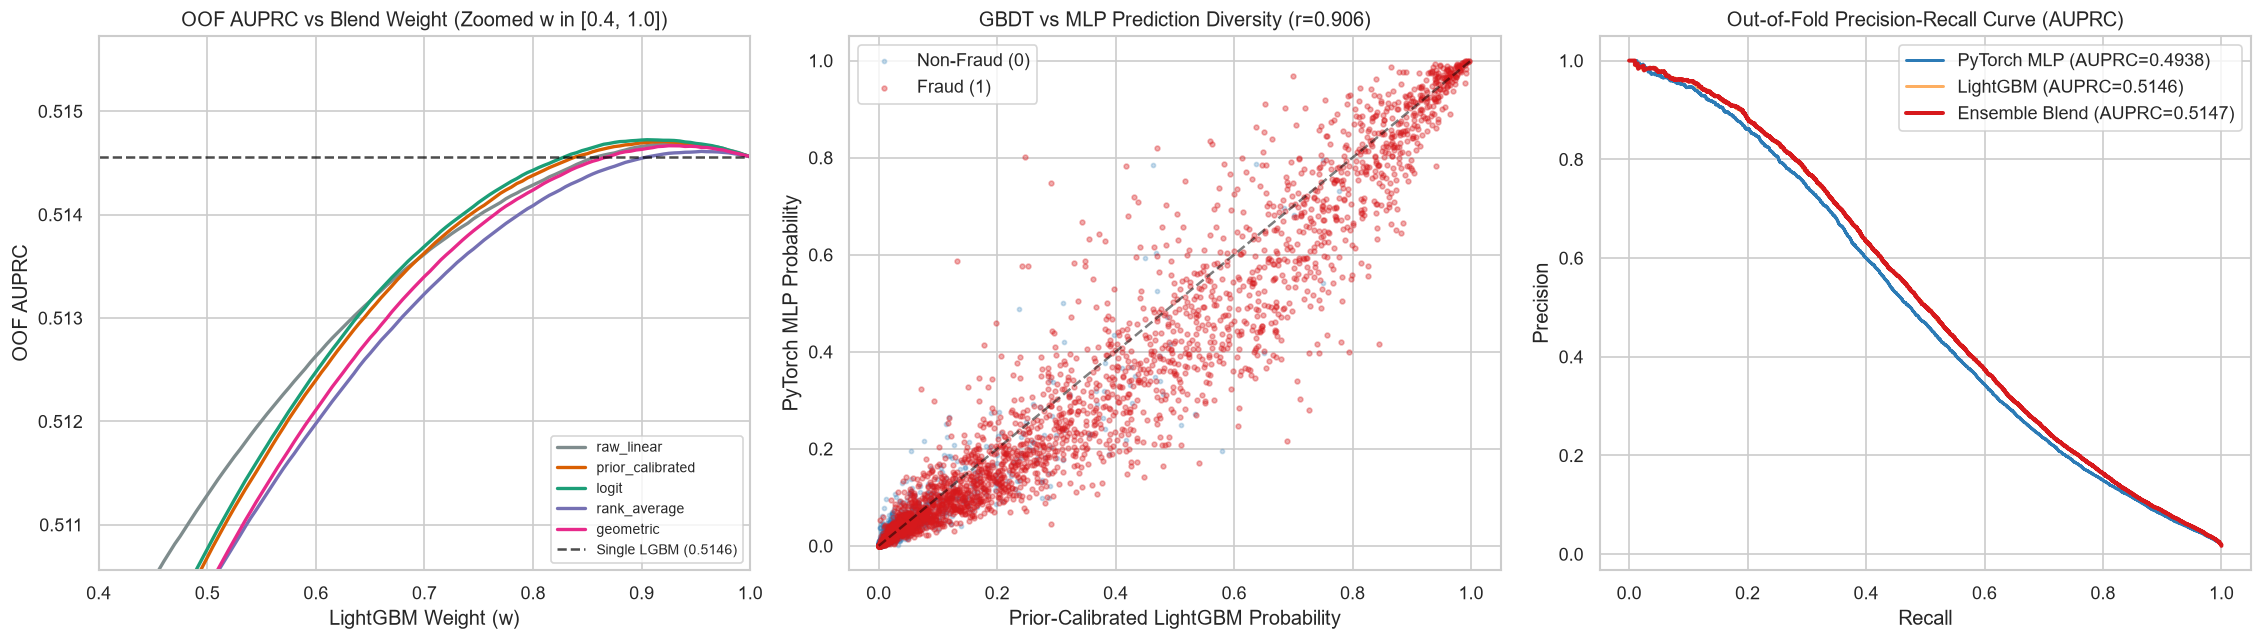

In [4]:
winner_method = str(leaderboard_df.iloc[0]["Method"])
winner = method_results[winner_method]

oof_blend = winner["global_oof"].astype(np.float64)
test_blend = winner["global_test"].astype(np.float64)

np.save("oof_blend.npy", oof_blend)
np.save("test_blend.npy", test_blend)

win_auprc = evaluate_auprc(y_true, oof_blend)
lgbm_fold_scores = [evaluate_auprc(y_true[folds == k], oof_lgbm[folds == k]) for k in range(5)]
nn_fold_scores = [evaluate_auprc(y_true[folds == k], oof_nn[folds == k]) for k in range(5)]
blend_fold_scores = [evaluate_auprc(y_true[folds == k], oof_blend[folds == k]) for k in range(5)]

print(f"Selected Winning Ensemble Method : {winner_method}")
print(f"Optimal Weights                  : {winner['global_weight_lgbm']:.4f} * LGBM + {1.0 - winner['global_weight_lgbm']:.4f} * NN")
print(f"Fold-wise Learned Weights        : {[round(w, 4) for w in winner['fold_weights']]}")
print(f"Final Global OOF AUPRC           : {win_auprc:.6f} (Nested OOF AUPRC: {winner['nested_oof_auprc']:.6f})")
print(f"Mean 5-Fold AUPRC                : {np.mean(blend_fold_scores):.6f} +/- {np.std(blend_fold_scores):.6f}")

fold_cmp_df = pd.DataFrame(
    {
        "Fold": list(range(5)),
        "MLP_NN_AUPRC": nn_fold_scores,
        "LightGBM_AUPRC": lgbm_fold_scores,
        "Ensemble_Blend_AUPRC": blend_fold_scores,
        "Gain_over_LGBM": np.array(blend_fold_scores) - np.array(lgbm_fold_scores),
        "Nested_Fold_w_LGBM": winner["fold_weights"],
    }
)
display(fold_cmp_df)

ensemble_meta = {
    "winning_method": winner_method,
    "weight_lgbm": float(winner["global_weight_lgbm"]),
    "weight_nn": float(1.0 - winner["global_weight_lgbm"]),
    "lgbm_spw_used_for_calibration": LGBM_SPW,
    "single_lgbm_oof_auprc": float(auprc_lgbm),
    "single_nn_oof_auprc": float(auprc_nn),
    "reference_070_030_raw_auprc": float(ref_raw_07_03),
    "reference_070_030_prior_cal_auprc": float(ref_cal_07_03),
    "nested_oof_auprc": float(winner["nested_oof_auprc"]),
    "global_oof_auprc": float(win_auprc),
    "mean_fold_auprc": float(np.mean(blend_fold_scores)),
    "std_fold_auprc": float(np.std(blend_fold_scores)),
    "gain_vs_lgbm": float(win_auprc - auprc_lgbm),
    "gain_vs_nn": float(win_auprc - auprc_nn),
    "fold_weights": [float(x) for x in winner["fold_weights"]],
    "fold_auprcs": [float(x) for x in blend_fold_scores],
    "diversity": div_stats,
    "oof_blend_mean": float(oof_blend.mean()),
    "test_blend_mean": float(test_blend.mean()),
}
with open("ensemble_metadata.json", "w", encoding="utf-8") as f:
    json.dump(ensemble_meta, f, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for m_name, color in [
    ("raw_linear", "#7f8c8d"),
    ("prior_calibrated", "#d95f02"),
    ("logit", "#1b9e77"),
    ("rank_average", "#7570b3"),
    ("geometric", "#e7298a"),
]:
    r_m = method_results[m_name]
    axes[0].plot(r_m["grid_weights"], r_m["grid_scores"], linewidth=2, label=m_name, color=color)

axes[0].axhline(auprc_lgbm, linestyle="--", color="black", alpha=0.7, label=f"Single LGBM ({auprc_lgbm:.4f})")
axes[0].set_xlim(0.4, 1.0)
axes[0].set_ylim(auprc_lgbm - 0.004, max(leaderboard_df["Global_OOF_AUPRC"]) + 0.001)
axes[0].set_xlabel("LightGBM Weight (w)")
axes[0].set_ylabel("OOF AUPRC")
axes[0].set_title("OOF AUPRC vs Blend Weight (Zoomed w in [0.4, 1.0])")
axes[0].legend(loc="lower right", fontsize=8.5)

rng = np.random.default_rng(42)
neg_sample = rng.choice(np.flatnonzero(y_true == 0), size=8000, replace=False)
pos_sample = rng.choice(np.flatnonzero(y_true == 1), size=3000, replace=False)
p_lgbm_cal = prior_calibrate_spw(oof_lgbm, LGBM_SPW)
axes[1].scatter(p_lgbm_cal[neg_sample], oof_nn[neg_sample], s=6, alpha=0.25, label="Non-Fraud (0)", color="#2c7bb6")
axes[1].scatter(p_lgbm_cal[pos_sample], oof_nn[pos_sample], s=8, alpha=0.35, label="Fraud (1)", color="#d7191c")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black", alpha=0.5)
axes[1].set_xlabel("Prior-Calibrated LightGBM Probability")
axes[1].set_ylabel("PyTorch MLP Probability")
axes[1].set_title(f"GBDT vs MLP Prediction Diversity (r={div_stats['pearson_all']:.3f})")
axes[1].legend(loc="upper left")

for label, preds, color, lw in [
    (f"PyTorch MLP (AUPRC={auprc_nn:.4f})", oof_nn, "#2c7bb6", 1.8),
    (f"LightGBM (AUPRC={auprc_lgbm:.4f})", oof_lgbm, "#fdae61", 1.8),
    (f"Ensemble Blend (AUPRC={win_auprc:.4f})", oof_blend, "#d7191c", 2.4),
]:
    p, r, _ = precision_recall_curve(y_true, preds)
    axes[2].plot(r, p, label=label, color=color, linewidth=lw)

axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Out-of-Fold Precision-Recall Curve (AUPRC)")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

print(
    f"Coreach.ai Comment -> Ensemble Blend (LGBM + MLP, {winner_method}, "
    f"w_lgbm={winner['global_weight_lgbm']:.3f}) | CV OOF AUPRC: {win_auprc:.4f} "
    f"(Delta vs Single LGBM: {win_auprc - auprc_lgbm:+.4f})"
)